# 현실의 데이터 30: 문서 종류 자동 분류

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/30_document_types.ipynb)

**분야**: 전문 서비스 &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: 문서 자동 분류 · 업무 자동화 (RPA) · 이미지 분류

> 스캔한 문서 1,200장. 편지일까, 영수증일까, 이력서일까?

**데이터**: RVL-CDIP (종류별 100장 판) (약 135MB). Harley et al. (2015). 스캔한 업무 문서 흑백 사진 16종류 (편지 · 양식 · 이메일 · 손글씨 · 광고 · 보고서 · 논문 · 사양서 · 파일 폴더 · 뉴스 · 예산 · 송장 · 발표 자료 · 설문 · 이력서 · 메모). 원본 40만 장 중 종류마다 75장씩 고른 판 (Hugging Face jordyvl/rvl_cdip_100_examples_per_class, 학습 800 · 시험 400).

산업 현장의 문제와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | 문서 사진 한 장 |
| ② 입력 X | 줄인 흑백 사진 (48×64) + 줄 · 칸마다 잉크 양 |
| ③ 출력 y | 16가지 문서 종류 |
| ④ 평가지표 | 정확도 + 종류별 재현율 |
| ⑤ 기준선 | 가장 흔한 종류 (모두 같은 수라 1/16) |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [Harley, Ufkes & Derpanis (2015) Evaluation of Deep Convolutional Nets for Document Image Classification and Retrieval, ICDAR (RVL-CDIP)](https://arxiv.org/abs/1502.07058)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

약 135MB. 처음엔 1~2분.

In [2]:
from PIL import Image
NAMES = ["letter", "form", "email", "handwritten", "advertisement", "scientific report", "scientific publication", "specification",
         "file folder", "news article", "budget", "invoice", "presentation", "questionnaire", "resume", "memo"]
BASE = "https://huggingface.co/api/datasets/jordyvl/rvl_cdip_100_examples_per_class/parquet/default/"
train = pd.read_parquet(download(BASE + "train/0.parquet", "data/rvlcdip100_train.parquet"))
test = pd.read_parquet(download(BASE + "test/0.parquet", "data/rvlcdip100_test.parquet"))
print(train.shape, test.shape)
print(pd.Series([NAMES[i] for i in train["label"]]).value_counts().to_dict())

(800, 2) (400, 2)
{'letter': 50, 'form': 50, 'email': 50, 'handwritten': 50, 'advertisement': 50, 'scientific report': 50, 'scientific publication': 50, 'specification': 50, 'file folder': 50, 'news article': 50, 'budget': 50, 'invoice': 50, 'presentation': 50, 'questionnaire': 50, 'resume': 50, 'memo': 50}


## 열어 보기

종류마다 한 장씩. 글자를 읽지 않아도 **모양 (배치)** 만으로 구분되는 종류가 있을까?

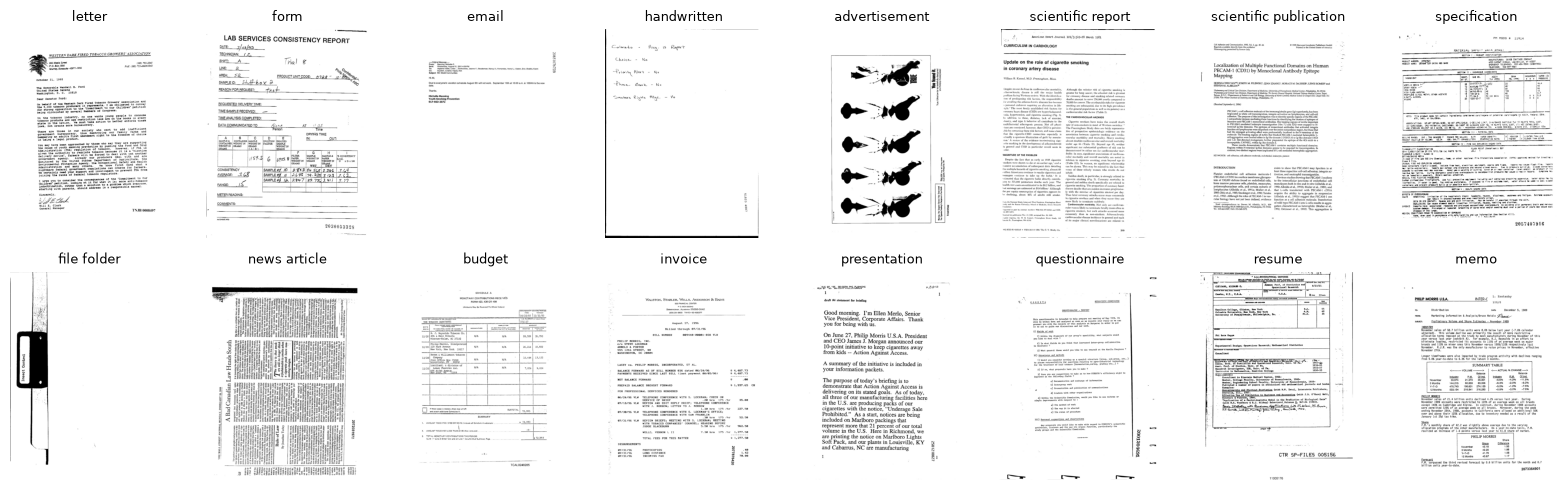

In [3]:
fig, axs = plt.subplots(2, 8, figsize=(16, 5))
for k, ax in enumerate(axs.ravel()):
    i = np.where(train["label"].values == k)[0][0]
    ax.imshow(Image.open(io.BytesIO(train["image"][i]["bytes"])), cmap="gray"); ax.set_title(NAMES[k], fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

## 문제 하나 골라 보기: 문서 사진 → 종류 (16가지)

글자는 읽지 않는다. 사진을 48×64 로 줄이고, 줄마다 · 칸마다 잉크 양 (어디에 글이 몰려 있나) 을 더해 랜덤 포레스트. 데이터가 나눠 둔 학습 · 시험을 그대로 쓴다.

In [4]:
from sklearn.ensemble import RandomForestClassifier

def layout_features(image_bytes):
    """Small grayscale picture + ink per row / column of one scanned page"""
    g = np.asarray(Image.open(io.BytesIO(image_bytes)).convert("L").resize((48, 64)), dtype=np.float32) / 255
    ink = 1 - g
    return np.r_[g.ravel(), ink.mean(1), ink.mean(0), ink.mean(), (ink > 0.5).mean()]

Xtr = np.stack([layout_features(b["bytes"]) for b in train["image"]])
Xte = np.stack([layout_features(b["bytes"]) for b in test["image"]])
m = RandomForestClassifier(500, random_state=0, n_jobs=-1).fit(Xtr, train["label"])
pred = m.predict(Xte); y = test["label"].values
print(f"baseline (one class): accuracy {1 / 16:.1%}")
print(f"random forest on page layout: accuracy {np.mean(pred == y):.1%}")
per = pd.Series(pred == y).groupby([NAMES[i] for i in y]).mean().sort_values()
print("hardest:", per.head(4).round(2).to_dict()); print("easiest:", per.tail(4).round(2).to_dict())

baseline (one class): accuracy 6.2%
random forest on page layout: accuracy 42.2%
hardest: {'presentation': 0.2, 'form': 0.24, 'invoice': 0.24, 'letter': 0.24}
easiest: {'scientific publication': 0.52, 'file folder': 0.76, 'email': 0.8, 'handwritten': 0.96}


**관찰**: 글자를 하나도 읽지 않고 모양만 봐도 기준선 (6%) 보다 훨씬 잘 맞힌다. 손글씨 · 이메일 · 파일 폴더처럼 모양이 뚜렷한 것은 쉽고, 발표 자료 · 양식 · 송장 · 편지는 서로 많이 헷갈린다. 이런 것은 글자를 읽어야 (OCR) 구분된다.

## 다른 문제로 바꿔 보기

- **업무 자동화**: 회사로 들어오는 문서를 종류별로 나눠 담당 부서로 보내기. 틀리면 어떤 손해가 큰가 (송장을 광고로 분류하면?)
- **글자도 쓰면**: OCR 로 글자를 뽑아 단어 빈도를 더하면 정확도가 얼마나 오를까?
- **더 어려운 문제로**: 종류를 맞힌 뒤 송장에서 '금액 · 날짜 · 업체' 칸을 찾아 읽기 (문서 이해).

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |